In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings('ignore') #ignoring some deprication warnings

**Step 1:**
-

In [3]:
!pip install yellowbrick

In [4]:
from yellowbrick.datasets import load_spam

In [5]:
X, y = load_spam()

In [6]:
X.head()

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,word_freq_conference,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total
0,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.0,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028
1,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.0,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259
2,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.0,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.0,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191
4,0.00,0.00,0.00,0.0,1.85,0.00,0.00,1.85,0.00,0.00,...,0.0,0.00,0.223,0.0,0.000,0.000,0.000,3.000,15,54


In [13]:
print(f"Types in X: {X.dtypes}")

Shape of X: word_freq_make                float64
word_freq_address             float64
word_freq_all                 float64
word_freq_3d                  float64
word_freq_our                 float64
word_freq_over                float64
word_freq_remove              float64
word_freq_internet            float64
word_freq_order               float64
word_freq_mail                float64
word_freq_receive             float64
word_freq_will                float64
word_freq_people              float64
word_freq_report              float64
word_freq_addresses           float64
word_freq_free                float64
word_freq_business            float64
word_freq_email               float64
word_freq_you                 float64
word_freq_credit              float64
word_freq_your                float64
word_freq_font                float64
word_freq_000                 float64
word_freq_money               float64
word_freq_hp                  float64
word_freq_hpl                 float64


In [15]:
print(f"Shape of X: {X.shape}")

Shape of X: (4600, 57)


In [16]:
print(f"Type in y: {y.dtypes}")

Type of y: int64


In [17]:
print(f"Shape of y: {y.shape}")

Shape of y: (4600,)


**Step 2:**
-

In [ ]:
print("Total missing values in X:", X.isnull().sum().sum())

Total missing values in X: 0


In [ ]:
print("Total missing values in y:", y.isnull().sum())

Total missing values in y: 0


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
_, X_small, _, y_small = train_test_split(X, y, test_size=0.04, random_state=0)

In [ ]:
print(f"Shape of X_small: {X_small.shape}")

Shape of X_small: (184, 57)


In [ ]:
print(f"Shape of y_small: {y_small.shape}")

Shape of y_small: (184,)


**Step 3:**
-

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
model = LogisticRegression(max_iter=2000)
model.fit(X,y)

LogisticRegression(max_iter=2000)

In [ ]:
X_two_cols = X.iloc[:, :2]

In [ ]:
model_X_two_cols = LogisticRegression(max_iter=2000)
model_X_two_cols.fit(X_two_cols, y)

LogisticRegression(max_iter=2000)

In [ ]:
model_x_small = LogisticRegression(max_iter=2000)
model_x_small.fit(X_small, y_small)

LogisticRegression(max_iter=2000)

**Step 4:**
-

In [ ]:
from sklearn.model_selection import cross_validate
validation_all = cross_validate(model, X, y, cv=5, scoring='accuracy', return_train_score=True)
validation_2_column = cross_validate(model_X_two_cols, X_two_cols, y, cv=5, scoring='accuracy', return_train_score=True)
validation_small = cross_validate(model_x_small, X_small, y_small, cv=5, scoring='accuracy', return_train_score=True)

In [ ]:
validation_all

{'fit_time': array([5.76709247, 7.83848548, 7.99043536, 1.98405051, 1.33065033]),
 'score_time': array([0.01665688, 0.0149231 , 0.00406075, 0.00396633, 0.00392556]),
 'test_score': array([0.92065217, 0.92826087, 0.9326087 , 0.94673913, 0.83586957]),
 'train_score': array([0.93070652, 0.92880435, 0.92690217, 0.92527174, 0.9451087 ])}

In [ ]:
validation_score_all = validation_all.get('test_score').mean()
training_score_all = validation_all.get('train_score').mean()
print(f"Training Score: {training_score_all:.3f}")
print(f"Validation Score: {validation_score_all:.3f}")

Training Score: 0.931
Validation Score: 0.913


In [ ]:
validation_2_column

{'fit_time': array([0.00753617, 0.00711513, 0.00638008, 0.00709701, 0.00740218]),
 'score_time': array([0.00274611, 0.00286293, 0.00273466, 0.00270057, 0.00269055]),
 'test_score': array([0.60543478, 0.61195652, 0.60217391, 0.61630435, 0.61304348]),
 'train_score': array([0.6201087 , 0.61304348, 0.61929348, 0.60842391, 0.62038043])}

In [ ]:
validation_score_2_col = validation_2_column.get('test_score').mean()
training_score_2_col = validation_2_column.get('train_score').mean()
print(f"Training Score: {training_score_2_col:.3f}")
print(f"Validation Score: {validation_score_2_col:.3f}")

Training Score: 0.616
Validation Score: 0.610


In [ ]:
validation_small

{'fit_time': array([0.21175909, 0.21480346, 0.22821498, 0.17223787, 0.12003636]),
 'score_time': array([0.00365114, 0.00366473, 0.00361395, 0.0036695 , 0.00359774]),
 'test_score': array([0.94594595, 0.89189189, 0.83783784, 0.81081081, 0.86111111]),
 'train_score': array([0.92517007, 0.93877551, 0.94557823, 0.92517007, 0.9527027 ])}

In [ ]:
validation_score_small = validation_small.get('test_score').mean()
training_score_small = validation_small.get('train_score').mean()
print(f"Training Score: {training_score_small:.3f}")
print(f"Validation Score: {validation_score_small:.3f}")

Training Score: 0.937
Validation Score: 0.870


**Step 5.1:**
-

In [ ]:
data = {
    'Data Size': [(X.shape, y.shape), (X_two_cols.shape, y.shape), (X_small.shape, y_small.shape)],
    'Training Accuracy': [training_score_all, training_score_2_col, training_score_small],
    'Validation Accuracy': [validation_score_all, validation_score_2_col, validation_score_small]
}
results = pd.DataFrame(data=data)
results

,Data Size,Training Accuracy,Validation Accuracy
0,"((4600, 57), (4600,))",0.931359,0.912826
1,"((4600, 2), (4600,))",0.616250,0.609783
2,"((184, 57), (184,))",0.937479,0.869520


**Step 5.2:**
-

<Axes: >

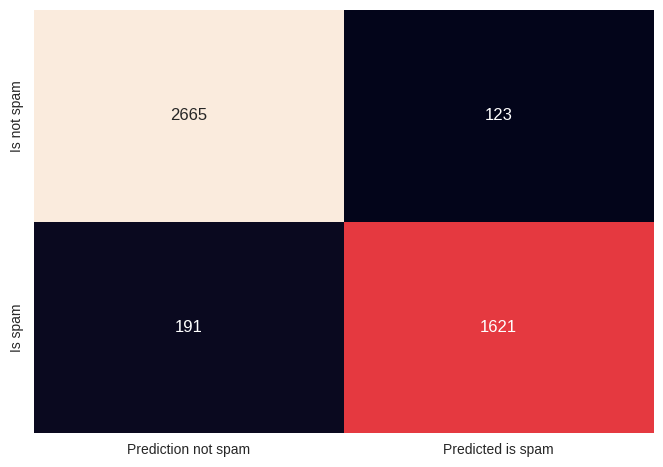

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y, model.predict(X))
sns.heatmap(cm, fmt='d', annot=True, cbar=False, yticklabels=["Is not spam", "Is spam"], xticklabels=["Prediction not spam", "Predicted is spam"])

**Questions**
-
1. With the entire dataset, we had training accuracy of about 93.1% and validation accuracy of about 91.3%. With model that used two columns (only 2 features), both accuracy scores reduced and we ended up with a training accuracy of 61.6% and a validation accuracy of about 61%. With a smaller dataset, training accuracy remained high with a score of 93.7% but validation accuracy dropped to about 87%.

2. When the amount of data in the set is changed, the model has less to work with. The X_small and y_small are only 186 values to split into 5 different valudation sets, as compared to the original 4600 values that were split 5 times. This ends up with the model being less confident in the results it produces as it did not have as much data it learned from. With the 2 column example, we ended up with underfitting, as we only had 2 features to compare to. For X_small, we had a generally good result but it seems like it is close to overfitting, as it had fewer values to work with it is likely it simply memorized the dataset.

3. Yes, changing the value for random_state when deriving X_small and y_small does make a difference for their results, the validation and training scores tend to increase. We believe this occurs as the random_state parameter is setting a seed related to the rows of the dataset, so that we get the same rows based on the integer value we supply. If we don't set anything, and ignore the random_state parameter entirely, it is randomized every time we run it. By giving it 0 as its parameter value, it uses the same 186 rows every time we run the function.

4. In this case, a false positive would be an email being flagged as spam, but is was not. A false negative would be a spam email being let through (flagged as safe), when it shouldn't have been. In our scenaario, a false negative would be worse, as a spam email being sent to your regular inbox carries more severe repercussions than a normal email being sent to spam. If someone were to click the link, it would lead to potential malware or a breach in privacy. The false positive is simply more of a nuisance.

**Part 2: Regression**
-

---



**Step 1:**
-

In [ ]:
!pip install ucimlrepo

**Step 2:**
-

In [ ]:
from ucimlrepo import fetch_ucirepo

auto_mpg = fetch_ucirepo(id=9)
X_reg = auto_mpg.data.features
y_reg = auto_mpg.data.targets

#with_car_name_preview = X_reg.join(auto_mpg.data.ids)
#with_car_name_preview.head()

X_reg.head()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin
0,307.0,8,130.0,3504,12.0,70,1
1,350.0,8,165.0,3693,11.5,70,1
2,318.0,8,150.0,3436,11.0,70,1
3,304.0,8,150.0,3433,12.0,70,1
4,302.0,8,140.0,3449,10.5,70,1


In [ ]:
print("Missing values in features:\n", X_reg.isnull().sum())

Missing values in features:
 displacement    0
cylinders       0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64


In [ ]:
X_reg['horsepower'] = X_reg['horsepower'].fillna(X_reg['horsepower'].median())
print("\nMissing values in target:", y_reg.isnull().sum().sum())



Missing values in target: 0


In [ ]:
X_numeric = X_reg.select_dtypes(include=[np.number])
print(f"\nShape of feature matrix X_numeric: {X_numeric.shape}")
print(f"Shape of target vector y_reg: {y_reg.shape}")


Shape of feature matrix X_numeric: (398, 7)
Shape of target vector y_reg: (398, 1)


In [ ]:
X_numeric.head()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin
0,307.0,8,130.0,3504,12.0,70,1
1,350.0,8,165.0,3693,11.5,70,1
2,318.0,8,150.0,3436,11.0,70,1
3,304.0,8,150.0,3433,12.0,70,1
4,302.0,8,140.0,3449,10.5,70,1


**Step 3:**
-

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_numeric, y_reg, test_size=0.10, random_state=0)

lin_reg = LinearRegression()

cv_reg_results = cross_validate(lin_reg, X_train, y_train, cv=5, scoring='r2', return_train_score=True)

training_r2_mean = cv_reg_results['train_score'].mean()
validation_r2_mean = cv_reg_results['test_score'].mean()

print(f"Mean CV Training R2 Score: {training_r2_mean:.3f}")
print(f"Mean CV Validation R2 Score: {validation_r2_mean:.3f}")

Mean CV Training R2 Score: 0.817
Mean CV Validation R2 Score: 0.808


**Step 4:**
-

In [ ]:
lin_reg.fit(X_train, y_train)

test_r2_score = lin_reg.score(X_test, y_test)
print(f"Final Testing R2 Score: {test_r2_score:.3f}")

Final Testing R2 Score: 0.845


**Step 5:**
-

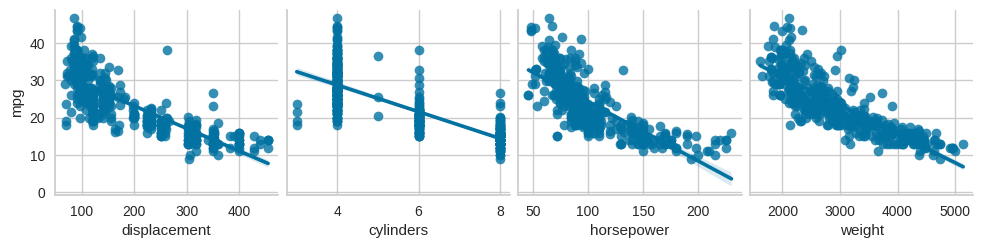

In [ ]:
plot_df = X_numeric.copy()
plot_df['mpg'] = y_reg

sns.pairplot(plot_df, y_vars=['mpg'], x_vars=X_numeric.columns.tolist()[:4], kind='reg')
plt.show()

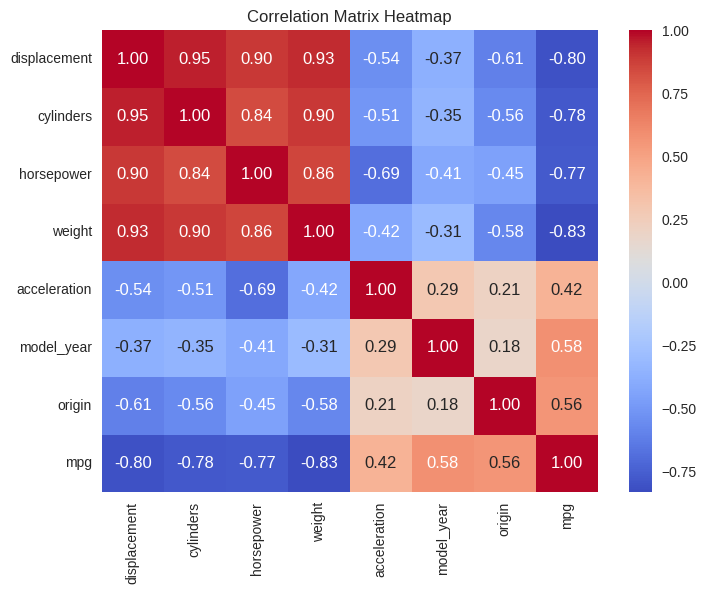

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(plot_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix Heatmap")
plt.show()

In [ ]:
print(f"Model Intercept: {lin_reg.intercept_[0]:.3f}\n")
print("Model Coefficients per Feature:")
for col, coef in zip(X_numeric.columns, lin_reg.coef_[0]):
    print(f"{col}: {coef:.3f}")

Model Intercept: -16.484

Model Coefficients per Feature:
displacement: 0.022
cylinders: -0.523
horsepower: -0.020
weight: -0.006
acceleration: 0.127
model_year: 0.725
origin: 1.512


In [ ]:
from sklearn.linear_model import Ridge
ridge = Ridge(alpha=100).fit(X_train, y_train)
print(ridge.intercept_)
print(ridge.coef_)

[-14.39209961]
[ 0.01233531 -0.22746718 -0.01322901 -0.00646167  0.11617975  0.71250012
  0.84347311]


**Questions**
-

---

1. Yes, the linear model worked well for our dataset. It is slightly parabolic but not enough that we would deem our model as a poor fit for this dataset.

2. No, the coefficients do not make sense when compared to the pairplot and correlation matrix. Both of the graphs are taking into account the affect of the other features on the final outcome of the relationship between the x feature and y feature. The coefficent is calculated under the assumption that all other features remain constant, therefore ignoring the affect other features would have on the final relationship.

3. With a default alpha value of 1.0, our values do not change significantly. Our intercept ends up as approximately -16.46, and our coefficients all move a tiny bit closer to 0. With higher alpha values there are mor significant changes (e.g., alpha=100 creates an origin coefficient of 0.84 and an intercept of -14). This small change is due to Ridge regression wanting to have smaller weights (coefficients) to result in a smaller slope overall, but majority of our coefficients are already very close to 0.